# EuroSAT dataset import and shared splits

Load EuroSAT using the same `eurosat_splits.csv` and `eurosat_classes.json` files used by `SqueezeNet_EuroSAT.ipynb`. The train, validation, and test assignments remain identical for later model comparison.

## Configuration

Set `data_dir` to an existing EuroSAT directory, or leave it as `None` to download the dataset through KaggleHub. Set `ROOT` explicitly if the kernel starts outside the repository folder.

In [8]:
from pathlib import Path
from types import SimpleNamespace
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "eurosat_data.py").is_file():
    raise FileNotFoundError(
        "Set ROOT to the repository folder containing eurosat_data.py"
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

args = SimpleNamespace(
    data_dir=None,  # Or Path("/path/to/EuroSAT")
    splits=ROOT / "eurosat_splits.csv",
    classes=ROOT / "eurosat_classes.json",
    
    batch_size=64,
    num_workers=0,
)

## Imports and shared manifest

`load_splits` validates the class order, labels, paths, and exact split counts before images are loaded.

In [9]:
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

from eurosat_data import load_splits, validate_images

rows, class_names = load_splits(args.splits, args.classes)
manifest = pd.DataFrame(rows)
NUM_CLASSES = len(class_names)

print(manifest["split"].value_counts())
print("Classes:", class_names)

split
train    18900
val       4050
test      4050
Name: count, dtype: int64
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## Locate and validate the EuroSAT images

The same KaggleHub dataset source and `EuroSAT` directory layout are used as in the SqueezeNet notebook.

In [10]:
if args.data_dir is None:
    import kagglehub
    dataset_path = kagglehub.dataset_download("apollo2506/eurosat-dataset")
    DATA_DIR = Path(dataset_path) / "EuroSAT"
else:
    DATA_DIR = Path(args.data_dir)

validate_images(rows, DATA_DIR)
print("Dataset directory:", DATA_DIR)
print("All manifest images found.")

Dataset directory: C:\Users\ASUS\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT
All manifest images found.


## Create train, validation, and test datasets

Use the same 64 x 64 RGB preprocessing and ImageNet normalization as SqueezeNet. No split is reshuffled or regenerated.

In [11]:
class EuroSATDataset(Dataset):
    def __init__(self, manifest, split, root, transform):
        self.frame = manifest[manifest["split"] == split].reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["relative_path"]) as image:
            image = self.transform(image.convert("RGB"))
        return image, int(row["label"])


image_transform = transforms.Compose([
    transforms.Resize(
        (64, 64),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

train_dataset = EuroSATDataset(manifest, "train", DATA_DIR, image_transform)
val_dataset = EuroSATDataset(manifest, "val", DATA_DIR, image_transform)
test_dataset = EuroSATDataset(manifest, "test", DATA_DIR, image_transform)

generator = torch.Generator().manual_seed(42)
loader_options = {
    "batch_size": args.batch_size,
    "num_workers": args.num_workers,
    "pin_memory": torch.cuda.is_available(),
}
train_loader = DataLoader(
    train_dataset, shuffle=True, generator=generator, **loader_options
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Train images: 18900
Validation images: 4050
Test images: 4050


## Model A: Standard CNN

Three blocks of Conv 3x3 → BatchNorm → ReLU → MaxPool 2x2 (32, 64, 128 filters), then global average pooling, Dense 64 + ReLU + Dropout(0.3), and a Dense 10 output.

- **Parameters:** 102,826 total (102,378 trainable + 448 BatchNorm running statistics), about 0.41 MB in float32.
- **`bias=False`** in the convolutions, because BatchNorm already has its own shift.
- **ReLU** needs only a comparison with zero (no exponential), so it is cheap on edge hardware.
- **Global average pooling** keeps the dense head small.
- **Output is raw logits.** `CrossEntropyLoss` applies softmax internally.

In [12]:
import torch
from torch import nn
from collections import OrderedDict


def create_model_a(input_shape=(64, 64, 3), num_classes=10):
    in_channels = input_shape[2]          # (H, W, C) -> C

    model = nn.Sequential(OrderedDict([
        # ---------------- Block 1 ----------------
        # bias=False, since we use batch normalization
        ("conv1", nn.Conv2d(in_channels, 32, kernel_size=3, padding=1, bias=False)),
        ("bn1", nn.BatchNorm2d(32)),
        ("relu1", nn.ReLU()),
        ("pool1", nn.MaxPool2d(kernel_size=2)),          # -> (32, 32, 32)

        # ---------------- Block 2 ----------------
        ("conv2", nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False)),
        ("bn2", nn.BatchNorm2d(64)),
        ("relu2", nn.ReLU()),
        ("pool2", nn.MaxPool2d(kernel_size=2)),          # -> (64, 16, 16)

        # ---------------- Block 3 ----------------
        ("conv3", nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False)),
        ("bn3", nn.BatchNorm2d(128)),
        ("relu3", nn.ReLU()),
        ("pool3", nn.MaxPool2d(kernel_size=2)),          # -> (128, 8, 8)

        # ---------------- Classifier Head ----------------
        # Global average pooling aggregates spatial dimensions into a compact 128-d vector
        ("gap", nn.AdaptiveAvgPool2d(1)),                # -> (128, 1, 1)
        ("flatten", nn.Flatten()),                       # -> (128)
        ("dense1", nn.Linear(128, 64)),
        ("relu_fc", nn.ReLU()),
        ("dropout", nn.Dropout(0.3)),
        ("predictions", nn.Linear(64, num_classes)),     # logits (no softmax)
    ]))

    # Same defaults as Keras: Glorot-uniform weights, zero biases
    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    return model


# Instantiate and verify parameters
model_a = create_model_a()
print(model_a)

trainable = sum(p.numel() for p in model_a.parameters() if p.requires_grad)
non_trainable = sum(b.numel() for n, b in model_a.named_buffers()
                    if "num_batches_tracked" not in n)
print(f"Trainable parameters:     {trainable:,}")       # 102,378
print(f"Non-trainable parameters: {non_trainable:,}")   # 448 (BatchNorm running stats)
print(f"Total parameters:         {trainable + non_trainable:,}")  # 102,826

# Shape check (PyTorch input is channels-first: batch, 3, 64, 64)
print(model_a(torch.randn(2, 3, 64, 64)).shape)         # torch.Size([2, 10])

Sequential(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=1)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense1): Linear(i

### Model B

In [13]:
class DepthwiseSeparableBlock(torch.nn.Module):
    """Depthwise 3x3 convolution followed by pointwise 1x1 convolution."""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = torch.nn.Sequential(
            torch.nn.Conv2d(
                in_channels=in_channels,
                out_channels=in_channels,
                kernel_size=3,
                padding=1,
                groups=in_channels,
                bias=False,
            ),
            torch.nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=1,
                bias=False,
            ),
            torch.nn.BatchNorm2d(out_channels),
            torch.nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class ModelBLightweightCNN(torch.nn.Module):
    def __init__(self, input_shape=(64, 64, 3), num_classes=10):
        super().__init__()
        height, width, input_channels = input_shape
        if (height, width) != (64, 64) or input_channels != 3:
            raise ValueError("input_shape must be (64, 64, 3)")

        self.features = torch.nn.Sequential(
            DepthwiseSeparableBlock(input_channels, 32),
            torch.nn.MaxPool2d(kernel_size=2),
            DepthwiseSeparableBlock(32, 64),
            torch.nn.MaxPool2d(kernel_size=2),
            DepthwiseSeparableBlock(64, 128),
            torch.nn.MaxPool2d(kernel_size=2),
        )
        self.classifier = torch.nn.Sequential(
            torch.nn.AdaptiveAvgPool2d((1, 1)),
            torch.nn.Flatten(),
            torch.nn.Linear(128, 64),
            torch.nn.ReLU(inplace=True),
            torch.nn.Dropout(p=0.3),
            torch.nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


def create_model_b(input_shape=(64, 64, 3), num_classes=10):
    return ModelBLightweightCNN(input_shape=input_shape, num_classes=num_classes)


# Instantiate and verify parameters.
model_b = create_model_b(num_classes=NUM_CLASSES)
print(model_b)

# Parameter threshold constraint validation.
total_params = sum(parameter.numel() for parameter in model_b.parameters())
assert total_params < 100_000, (
    f"Parameter count {total_params} exceeds the 100k limit!"
)
print(
    f"\n[PASS] Model B Parameter Count: {total_params:,} "
    "(Strictly under 100,000 threshold)"
)

ModelBLightweightCNN(
  (features): Sequential(
    (0): DepthwiseSeparableBlock(
      (block): Sequential(
        (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=3, bias=False)
        (1): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (3): ReLU(inplace=True)
      )
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): DepthwiseSeparableBlock(
      (block): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (3): ReLU(inplace=True)
      )
    )
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Dep

## Optimizer comparison 

Three optimizers are trained on Model B for 7 epochs each, starting from identical initial weights (same seed), and compared on validation loss and accuracy:

- **Adam** (lr = 0.001): adapts the step size for each parameter, so it usually converges fast with little tuning.
- **Standard SGD** (lr = 0.01): a plain gradient step. It is simple but slower, and can be noisy.
- **SGD with momentum** (lr = 0.01, β = 0.9): keeps a running average of past gradients, which smooths the noise and speeds up progress along consistent directions.

**Momentum:** a higher β (such as 0.9) gives faster, smoother convergence, but too high a value can overshoot the minimum. With β = 0, it is plain SGD.

The curves and the summary table show which optimizer converges fastest and reaches the lowest validation loss.

Using device: cuda
Starting optimizer comparison study on Model B architecture...

--> Training with: Adam (lr=0.001)
Epoch 1/7 | loss=1.2006 acc=0.5814 | val_loss=0.9006 val_acc=0.6719 | 41.7s
Epoch 2/7 | loss=0.8163 acc=0.7149 | val_loss=0.6891 val_acc=0.7543 | 23.2s
Epoch 3/7 | loss=0.7204 acc=0.7467 | val_loss=0.6236 val_acc=0.7746 | 22.6s
Epoch 4/7 | loss=0.6642 acc=0.7691 | val_loss=0.5479 val_acc=0.7993 | 23.0s
Epoch 5/7 | loss=0.6224 acc=0.7811 | val_loss=0.6201 val_acc=0.7758 | 23.3s
Epoch 6/7 | loss=0.5783 acc=0.7988 | val_loss=0.5332 val_acc=0.8099 | 23.3s
Epoch 7/7 | loss=0.5382 acc=0.8128 | val_loss=0.4792 val_acc=0.8304 | 21.0s

--> Training with: Standard SGD (lr=0.01)
Epoch 1/7 | loss=1.8880 acc=0.3717 | val_loss=1.5227 val_acc=0.5338 | 19.8s
Epoch 2/7 | loss=1.4094 acc=0.5161 | val_loss=1.2102 val_acc=0.6094 | 20.0s
Epoch 3/7 | loss=1.2092 acc=0.5804 | val_loss=1.0832 val_acc=0.6175 | 19.8s
Epoch 4/7 | loss=1.0978 acc=0.6169 | val_loss=1.1632 val_acc=0.5652 | 20.5s
Epo

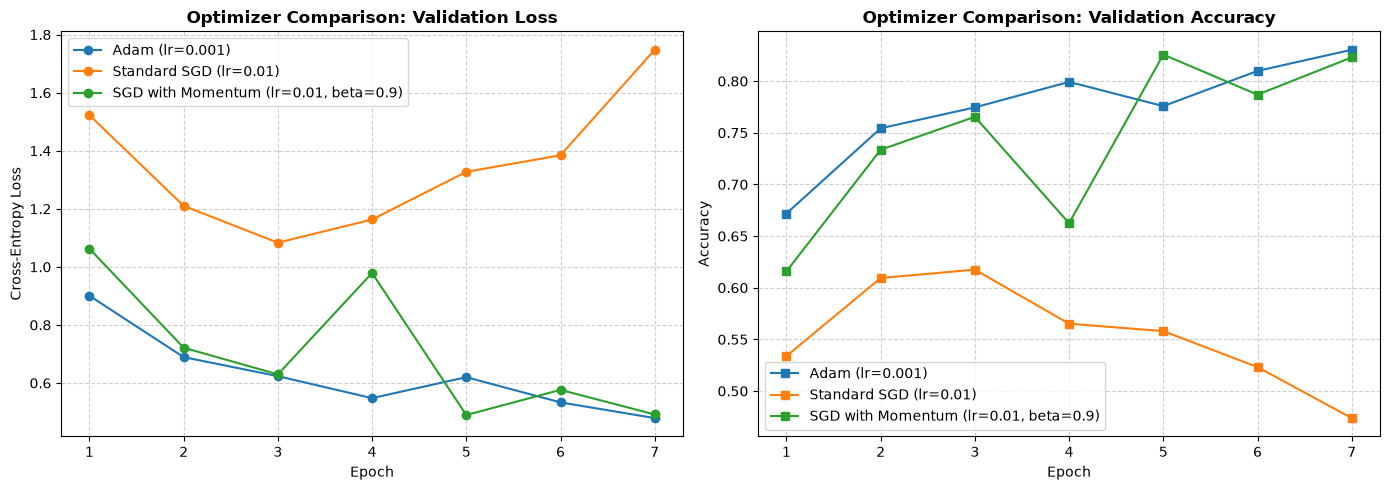


Optimizer                                | Final Val Loss | Final Val Acc (%)
Adam (lr=0.001)                          | 0.4792         | 83.04         %
Standard SGD (lr=0.01)                   | 1.7479         | 47.38         %
SGD with Momentum (lr=0.01, beta=0.9)    | 0.4915         | 82.30         %


In [14]:
import time
import matplotlib.pyplot as plt
import torch
from torch import nn

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using device: {device}")

# -------------------------------------------------------------------------
# Define the 3 Optimizers for Empirical Comparison
# Each entry builds the optimizer from a model's parameters.
# -------------------------------------------------------------------------
EPOCHS_TUNE = 7  # Diagnostic epoch count to compare convergence profiles

optimizers_to_test = {
    "Adam (lr=0.001)":
        lambda params: torch.optim.Adam(params, lr=1e-3),
    "Standard SGD (lr=0.01)":
        lambda params: torch.optim.SGD(params, lr=1e-2, momentum=0.0),
    "SGD with Momentum (lr=0.01, beta=0.9)":
        lambda params: torch.optim.SGD(params, lr=1e-2, momentum=0.9),
}

criterion = nn.CrossEntropyLoss()   # takes logits directly (no softmax in model)


def run_epoch(model, loader, optimizer=None):
    """One pass over the loader. Trains if an optimizer is given, else evaluates."""
    training = optimizer is not None
    model.train(training)
    total_loss, total_correct, total_samples = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples


histories = {}

print("Starting optimizer comparison study on Model B architecture...\n")

for opt_name, make_optimizer in optimizers_to_test.items():
    print(f"--> Training with: {opt_name}")

    # Same seed -> identical initial weights for every optimizer (fair comparison)
    torch.manual_seed(42)
    model_exp = create_model_b().to(device)
    optimizer = make_optimizer(model_exp.parameters())

    hist = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(1, EPOCHS_TUNE + 1):
        start = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model_exp, train_loader, optimizer)
        va_loss, va_acc = run_epoch(model_exp, val_loader)
        elapsed = time.perf_counter() - start

        hist["train_loss"].append(tr_loss)
        hist["train_accuracy"].append(tr_acc)
        hist["val_loss"].append(va_loss)
        hist["val_accuracy"].append(va_acc)

        print(f"Epoch {epoch}/{EPOCHS_TUNE} | "
              f"loss={tr_loss:.4f} acc={tr_acc:.4f} | "
              f"val_loss={va_loss:.4f} val_acc={va_acc:.4f} | {elapsed:.1f}s")

    histories[opt_name] = hist
    print()

# -------------------------------------------------------------------------
# Plot Comparative Convergence Curves
# -------------------------------------------------------------------------
plt.figure(figsize=(14, 5))

# Subplot 1: Validation Loss Convergence
plt.subplot(1, 2, 1)
for opt_name, hist in histories.items():
    plt.plot(range(1, EPOCHS_TUNE + 1), hist["val_loss"], marker="o", label=opt_name)
plt.title("Optimizer Comparison: Validation Loss", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# Subplot 2: Validation Accuracy Convergence
plt.subplot(1, 2, 2)
for opt_name, hist in histories.items():
    plt.plot(range(1, EPOCHS_TUNE + 1), hist["val_accuracy"], marker="s", label=opt_name)
plt.title("Optimizer Comparison: Validation Accuracy", fontsize=12, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Summary Performance Table
# -------------------------------------------------------------------------
print("\n" + "=" * 70)
print(f"{'Optimizer':<40} | {'Final Val Loss':<14} | {'Final Val Acc (%)':<14}")
print("=" * 70)
for opt_name, hist in histories.items():
    final_loss = hist["val_loss"][-1]
    final_acc = hist["val_accuracy"][-1] * 100
    print(f"{opt_name:<40} | {final_loss:<14.4f} | {final_acc:<14.2f}%")
print("=" * 70)

### Train Models


In [15]:
import time

EPOCHS = 20
LEARNING_RATE = 1e-3


class EpochTimerCallback:
    def on_train_begin(self):
        self.epoch_times = []

    def on_epoch_begin(self):
        self.epoch_start = time.perf_counter()

    def on_epoch_end(self):
        elapsed = time.perf_counter() - self.epoch_start
        self.epoch_times.append(elapsed)


In [16]:
# -------------------------------------------------------------------------
# 1. Train Model A (Standard CNN)
# -------------------------------------------------------------------------
print("=" * 60)
print("TRAINING MODEL A (Standard CNN)")
print("=" * 60)

model_a = create_model_a(num_classes=NUM_CLASSES).to(device)
optimizer_a = torch.optim.Adam(model_a.parameters(), lr=LEARNING_RATE)
timer_a = EpochTimerCallback()
timer_a.on_train_begin()

history_a = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

for epoch in range(1, EPOCHS + 1):
    timer_a.on_epoch_begin()
    train_loss, train_accuracy = run_epoch(
        model_a,
        train_loader,
        optimizer=optimizer_a,
    )
    val_loss, val_accuracy = run_epoch(model_a, val_loader)
    timer_a.on_epoch_end()

    history_a["loss"].append(train_loss)
    history_a["accuracy"].append(train_accuracy)
    history_a["val_loss"].append(val_loss)
    history_a["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"loss={train_loss:.4f} acc={train_accuracy:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_accuracy:.4f} | "
        f"{timer_a.epoch_times[-1]:.1f}s"
    )

TRAINING MODEL A (Standard CNN)
Epoch 1/20 | loss=1.0445 acc=0.6396 | val_loss=0.8070 val_acc=0.7042 | 20.1s
Epoch 2/20 | loss=0.7147 acc=0.7556 | val_loss=0.5413 val_acc=0.8012 | 19.9s
Epoch 3/20 | loss=0.6217 acc=0.7834 | val_loss=0.5846 val_acc=0.7864 | 26.8s
Epoch 4/20 | loss=0.5553 acc=0.8111 | val_loss=0.7111 val_acc=0.7447 | 28.3s
Epoch 5/20 | loss=0.5119 acc=0.8246 | val_loss=0.6700 val_acc=0.7694 | 27.8s
Epoch 6/20 | loss=0.4603 acc=0.8415 | val_loss=0.4862 val_acc=0.8356 | 28.4s
Epoch 7/20 | loss=0.4252 acc=0.8544 | val_loss=0.3711 val_acc=0.8696 | 27.0s
Epoch 8/20 | loss=0.4040 acc=0.8639 | val_loss=0.3274 val_acc=0.8842 | 28.0s
Epoch 9/20 | loss=0.3713 acc=0.8744 | val_loss=0.5395 val_acc=0.8148 | 27.9s
Epoch 10/20 | loss=0.3578 acc=0.8792 | val_loss=0.5087 val_acc=0.8247 | 27.9s
Epoch 11/20 | loss=0.3400 acc=0.8849 | val_loss=0.4704 val_acc=0.8365 | 28.2s
Epoch 12/20 | loss=0.3184 acc=0.8913 | val_loss=0.2785 val_acc=0.9044 | 28.1s
Epoch 13/20 | loss=0.3007 acc=0.8995 | va

In [17]:
# -------------------------------------------------------------------------
# 2. Train Model B (Lightweight Depthwise Separable CNN)
# -------------------------------------------------------------------------
print("\n" + "=" * 60)
print("TRAINING MODEL B (Lightweight SepConv CNN)")
print("=" * 60)

model_b = create_model_b(num_classes=NUM_CLASSES).to(device)
optimizer_b = torch.optim.Adam(model_b.parameters(), lr=LEARNING_RATE)
timer_b = EpochTimerCallback()
timer_b.on_train_begin()

history_b = {
    "loss": [],
    "accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

for epoch in range(1, EPOCHS + 1):
    timer_b.on_epoch_begin()
    train_loss, train_accuracy = run_epoch(
        model_b,
        train_loader,
        optimizer=optimizer_b,
    )
    val_loss, val_accuracy = run_epoch(model_b, val_loader)
    timer_b.on_epoch_end()

    history_b["loss"].append(train_loss)
    history_b["accuracy"].append(train_accuracy)
    history_b["val_loss"].append(val_loss)
    history_b["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"loss={train_loss:.4f} acc={train_accuracy:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_accuracy:.4f} | "
        f"{timer_b.epoch_times[-1]:.1f}s"
    )

# -------------------------------------------------------------------------
# 3. Save Models to Disk for Accurate Disk Footprint Measurement
# -------------------------------------------------------------------------
import os

os.makedirs("./saved_models", exist_ok=True)
path_a = "./saved_models/model_a.pt"
path_b = "./saved_models/model_b.pt"

# Save weights only (state_dict), the standard PyTorch way
torch.save(model_a.state_dict(), path_a)
torch.save(model_b.state_dict(), path_b)

print(f"Model A: {os.path.getsize(path_a) / 1024:.1f} KB on disk")
print(f"Model B: {os.path.getsize(path_b) / 1024:.1f} KB on disk")


TRAINING MODEL B (Lightweight SepConv CNN)
Epoch 1/20 | loss=1.2459 acc=0.5515 | val_loss=0.8194 val_acc=0.7081 | 28.3s
Epoch 2/20 | loss=0.7864 acc=0.7214 | val_loss=0.6719 val_acc=0.7563 | 27.6s
Epoch 3/20 | loss=0.6751 acc=0.7596 | val_loss=0.6059 val_acc=0.7753 | 27.9s
Epoch 4/20 | loss=0.6186 acc=0.7806 | val_loss=0.5350 val_acc=0.8010 | 29.3s
Epoch 5/20 | loss=0.5807 acc=0.7983 | val_loss=0.5190 val_acc=0.8104 | 28.2s
Epoch 6/20 | loss=0.5503 acc=0.8074 | val_loss=0.4890 val_acc=0.8284 | 29.9s
Epoch 7/20 | loss=0.5187 acc=0.8196 | val_loss=0.5064 val_acc=0.8291 | 31.0s
Epoch 8/20 | loss=0.4811 acc=0.8331 | val_loss=0.5244 val_acc=0.8146 | 28.4s
Epoch 9/20 | loss=0.4618 acc=0.8406 | val_loss=0.4634 val_acc=0.8249 | 27.7s
Epoch 10/20 | loss=0.4376 acc=0.8487 | val_loss=0.4989 val_acc=0.8072 | 29.1s
Epoch 11/20 | loss=0.4275 acc=0.8525 | val_loss=0.4827 val_acc=0.8252 | 28.4s
Epoch 12/20 | loss=0.4015 acc=0.8615 | val_loss=0.4369 val_acc=0.8459 | 28.4s
Epoch 13/20 | loss=0.4021 acc

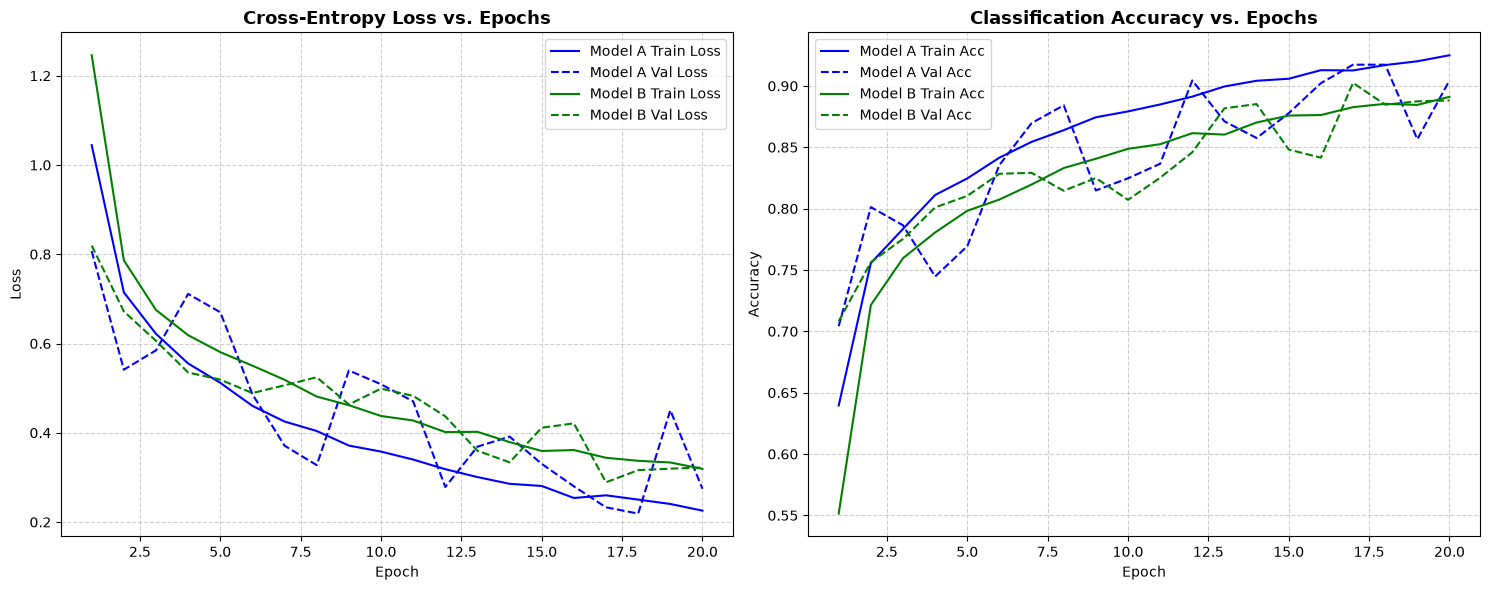

In [18]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------------
# 4. Plot Training & Validation Loss/Accuracy Curves
# -------------------------------------------------------------------------
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(15, 6))

# Subplot 1: Loss curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_a['loss'], 'b-', label='Model A Train Loss')
plt.plot(epochs_range, history_a['val_loss'], 'b--', label='Model A Val Loss')
plt.plot(epochs_range, history_b['loss'], 'g-', label='Model B Train Loss')
plt.plot(epochs_range, history_b['val_loss'], 'g--', label='Model B Val Loss')
plt.title("Cross-Entropy Loss vs. Epochs", fontsize=13, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

# Subplot 2: Accuracy curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_a['accuracy'], 'b-', label='Model A Train Acc')
plt.plot(epochs_range, history_a['val_accuracy'], 'b--', label='Model A Val Acc')
plt.plot(epochs_range, history_b['accuracy'], 'g-', label='Model B Train Acc')
plt.plot(epochs_range, history_b['val_accuracy'], 'g--', label='Model B Val Acc')
plt.title("Classification Accuracy vs. Epochs", fontsize=13, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()